# Fig. A4: land area

In [1]:
from helpers import *
import os
from netCDF4 import Dataset

# PaleoDEMs not included: see topography/README.md

def land_area(nc_path, radius=6.371e6):
    # area [m2] of the cells with elevation z > 0 on a regular lat-lon grid
    with Dataset(nc_path) as nc:
        z, lat, lon = nc["z"][:], nc["lat"][:], nc["lon"][:]
    _, lat2d = np.meshgrid(lon, lat)
    dlat = np.deg2rad(np.abs(lat[1] - lat[0]))
    dlon = np.deg2rad(np.abs(lon[1] - lon[0]))
    area_grid = radius**2 * dlat * dlon * np.cos(np.deg2rad(lat2d))
    return float(np.sum(area_grid[z > 0]))

ages, land_areas = [], []
for name in os.listdir("topography/paleodems"):
    if not name.endswith(".nc"):
        continue
    age = float(name.split("_")[-1][:-5]) # e.g. ..._300Ma.nc -> 300
    if age <= 540:
        ages.append(age)
        land_areas.append(land_area(os.path.join("topography/paleodems", name)))
order = np.argsort(ages)
ages, land_areas = np.array(ages)[order], np.array(land_areas)[order]
land_area_720 = land_area("topography/reconstructions/720Ma_Mer21.nc")
land_area_720_li23 = land_area("topography/reconstructions/720Ma_Li23.nc")

total_area = 4 * np.pi * (6.371e6)**2 # Earth surface area [m2]

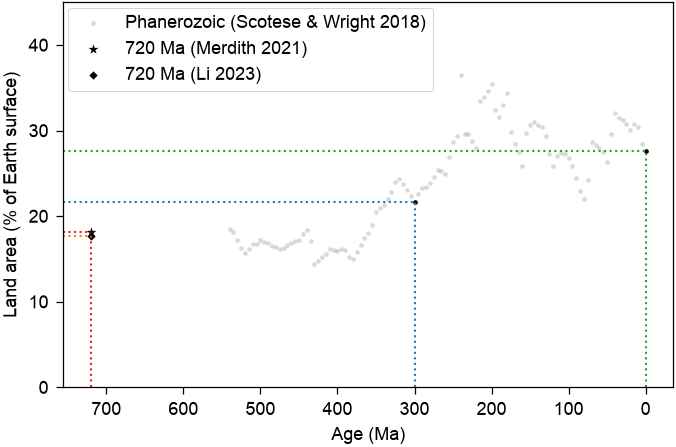

In [2]:
highlight_colors = {0: "tab:green", 300: "tab:blue", 720: "tab:red"}
highlight_pcts = {
    0:   land_areas[ages == 0][0] / total_area * 100,
    300: land_areas[ages == 300][0] / total_area * 100,
    720: land_area_720 / total_area * 100,
}

fig, ax = plt.subplots(figsize=(MEDIUM_WIDTH, MEDIUM_HEIGHT))

dim_mask = ~np.isin(ages, [0, 300])
ax.scatter(ages[dim_mask], land_areas[dim_mask]/total_area*100, color="k", s=5, alpha=0.15, linewidth=0,
           label="Phanerozoic (Scotese & Wright 2018)")
ax.scatter(ages[~dim_mask], land_areas[~dim_mask]/total_area*100, color="k", s=5, alpha=1, linewidth=0)
ax.scatter(720, land_area_720/total_area*100, color="k", marker="*", s=25, linewidth=0, label="720 Ma (Merdith 2021)")
ax.scatter(720, land_area_720_li23/total_area*100, color="k", marker="D", s=8, linewidth=0, label="720 Ma (Li 2023)")

ax.set_xlabel("Age (Ma)")
ax.set_ylabel("Land area (% of Earth surface)")
ax.set_ylim(0, 50)
ax.invert_xaxis()
ax.legend(loc="upper left")

# crosshairs at the modeled configurations; limits saved first so they don't autoscale
x0, x1 = ax.get_xlim()
y0 = ax.get_ylim()[0]
for age, pct in highlight_pcts.items():
    ax.plot([x0, age], [pct, pct], color=highlight_colors[age], ls=":", alpha=1)
    ax.plot([age, age], [y0, pct], color=highlight_colors[age], ls=":", alpha=1)
ax.plot([x0, 720], [land_area_720_li23/total_area*100] * 2, color="tab:orange", ls=":", alpha=1)
ax.set_xlim(x0, x1)
ax.set_ylim(y0, 45) # room above the data for the legend
ax.set_yticks(range(0, 41, 10))

plt.tight_layout()
plt.savefig("figs/land_area.pdf", bbox_inches="tight")
plt.show()